# Student Placement prediction Model

1. Load the Data set

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('placement.csv')

print(df)

    Unnamed: 0  cgpa     iq  placement
0            0   6.8  123.0          1
1            1   5.9  106.0          0
2            2   5.3  121.0          0
3            3   7.4  132.0          1
4            4   5.8  142.0          0
..         ...   ...    ...        ...
95          95   4.3  200.0          0
96          96   4.4   42.0          0
97          97   6.7  182.0          1
98          98   6.3  103.0          1
99          99   6.2  113.0          1

[100 rows x 4 columns]


2. Preprocess + EDA + Feature Selection

In [42]:
print(df.shape)
print(df.head())
print(df.info())
print(df.describe())

(100, 4)
   Unnamed: 0  cgpa     iq  placement
0           0   6.8  123.0          1
1           1   5.9  106.0          0
2           2   5.3  121.0          0
3           3   7.4  132.0          1
4           4   5.8  142.0          0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB
None
       Unnamed: 0        cgpa          iq   placement
count  100.000000  100.000000  100.000000  100.000000
mean    49.500000    5.991000  123.580000    0.500000
std     29.011492    1.143634   39.944198    0.502519
min      0.000000    3.300000   37.000000    0.000000
25%     24.750000    5.075000  101.500000    0.000000
50%     49.500000    6.000000  127.

In [43]:
# remove the first column because, there is no need of it

df = df.iloc[:,1:]
print(df)

    cgpa     iq  placement
0    6.8  123.0          1
1    5.9  106.0          0
2    5.3  121.0          0
3    7.4  132.0          1
4    5.8  142.0          0
..   ...    ...        ...
95   4.3  200.0          0
96   4.4   42.0          0
97   6.7  182.0          1
98   6.3  103.0          1
99   6.2  113.0          1

[100 rows x 3 columns]


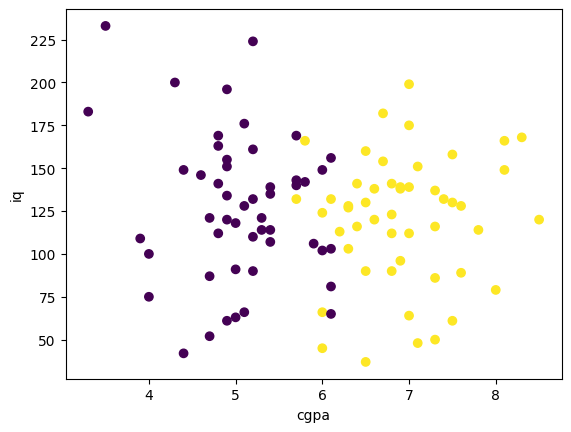

In [44]:
# EDA

plt.scatter(df['cgpa'],df['iq'], c=df['placement'])
plt.xlabel('cgpa')
plt.ylabel('iq')
plt.show()

3. Extract Input and Output Columns

In [45]:
X = df.iloc[:,0:2]
Y = df.iloc[:,2]

print(X)  # input columns
print(Y)  # output columns

    cgpa     iq
0    6.8  123.0
1    5.9  106.0
2    5.3  121.0
3    7.4  132.0
4    5.8  142.0
..   ...    ...
95   4.3  200.0
96   4.4   42.0
97   6.7  182.0
98   6.3  103.0
99   6.2  113.0

[100 rows x 2 columns]
0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64


4. Train Test Split Data

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.1) # 10% of data goes for test

print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(90, 2)
(10, 2)
(90,)
(10,)


5. Scaling the data

In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

6. Train the Model

In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

# model training
model.fit(X_train,Y_train)

LogisticRegression()

7. Evaluate the Model

In [49]:
Y_prediction = model.predict(X_test)

from sklearn.metrics import accuracy_score

print(accuracy_score(Y_test,Y_prediction))

1.0


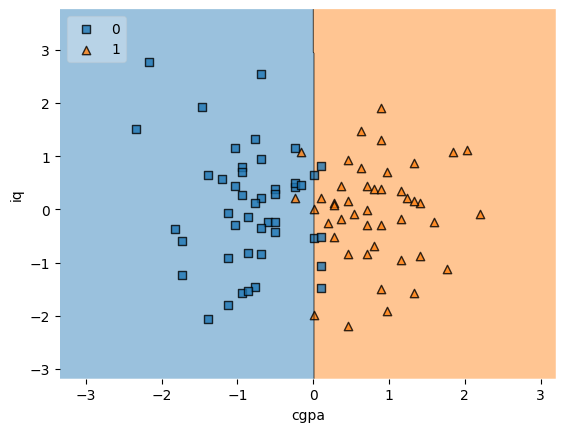

In [56]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X_train, y=Y_train.values, clf=model, legend=2)
plt.xlabel('cgpa')
plt.ylabel('iq')
plt.show()